In [1]:
from google.colab import files

uploaded = files.upload()

Saving soybean_archx_lstm_project.zip to soybean_archx_lstm_project.zip


In [2]:
import zipfile
import os

zip_path = "/content/soybean_archx_lstm_project.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

project_path = "/content/soybean_archx_lstm_project"

print("Project extracted:", os.path.exists(project_path))
print("Project files:", os.listdir(project_path))

Project extracted: True
Project files: ['requirements.txt', 'data', '__pycache__', 'run_models.py', 'outputs', 'README.md']


In [3]:
%cd /content/soybean_archx_lstm_project

!pip install -q -r requirements.txt

/content/soybean_archx_lstm_project


In [4]:
import pandas as pd
import numpy as np
import sklearn
import tensorflow as tf
import arch

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("ARCH:", arch.__version__)
print("All required libraries imported successfully.")

Pandas: 2.2.3
NumPy: 2.1.3
TensorFlow: 2.21.0
ARCH: 8.0.0
All required libraries imported successfully.


In [5]:
%cd /content/soybean_archx_lstm_project

!python run_models.py

/content/soybean_archx_lstm_project
I0000 00:00:1792867398.398369    1722 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792867402.028930    1722 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1792867402.751846    1722 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)

INPUT AUDIT
   series  raw_rows  duplicate_date_rows_aggregated first_date  last_date  unique_daily_dates                                                                     unit  raw_valid_rows  observed_min  observed_median  observed_max
   Indore    4386.0                               0 2011-01-01 2025-12-31                4386                         INR/quintal (assumed from Agmarknet modal price)             NaN           NaN              NaN           NaN
   Gondal    4354.0                               0 2011-01-03 2025-12-31                4354       

In [6]:
import pandas as pd

results = pd.read_csv("outputs/out_of_sample_metrics.csv")
display(results.sort_values(["market", "RMSE"]))

,market,model,RMSE,MAE,MAPE_percent
6,Gondal,LSTM (price-only),116.038608,82.266909,1.927136
4,Gondal,Naive last-week price,116.056864,81.925000,1.919270
5,Gondal,ARCHX (ARX mean + ARCH(1) variance),116.067739,82.658338,1.935474
7,Gondal,LSTM-X (lagged crude oil),116.853878,82.277268,1.928305
2,Indore,LSTM (price-only),201.601196,146.936920,3.367401
0,Indore,Naive last-week price,203.294496,147.275988,3.376023
1,Indore,ARCHX (ARX mean + ARCH(1) variance),203.380441,147.635152,3.384732
3,Indore,LSTM-X (lagged crude oil),204.107865,147.989705,3.392250


In [10]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/soybean_forecasting_results",
    "zip",
    "/content/soybean_archx_lstm_project/outputs"
)

files.download("/content/soybean_forecasting_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files
files.upload()

Saving soybean_forecasting_results.zip to soybean_forecasting_results (1).zip


{'soybean_forecasting_results (1).zip': b'PK\x03\x04\x14\x00\x00\x00\x08\x00h\x95X]=\xfb@7\x17\x01\x00\x00\xe1\x01\x00\x00\x0f\x00\x00\x00input_audit.csv\x9d\x911O\xc30\x10\x85\xf7\xfe\n\x8f ]\xd28N\xda"&\xa4\x16\x94\xa5CQY#\'\xbeF\x16\x8e\xdd\x9e\xe3\x16\xfe=N\x10\xa8\x15\x1b\x96e\xdd{O\xf7\x9de{$\x8d\x1eH^jr\x17\x0f*\x1c\x8dn\xe5\x80\xb5\x1a\x8f\xd1\xabe\xd7\x11vQ*8h\xf2\xc3\x14\x81\x91?U\xb0\xfa\x14\xc6\x06m>\'\xc7\x8f\xd60A\xcf\xd2h\xf5\x8dv\x8dG:\xa3\xaa{m\xaf\x04*-\xaf\xb5\xfc\x98UV9B(\xc4j\x91f\x90A\x9eq\x9ed\xe3\x8ee^&<O\x04\x9fb\xa8\xb6\xbb\xf9)h;H\xc3\xee\xa4\xf7!\xf2\xd8\x81\\\xcf\x9e\xba^\xd2\xbb\xc5\x81\xf5N\xc5\xf4H\xba\xc5{\x88k\xf6\xe2lt"\xa0,n\xf9\xe2\x96_\x16\xff\xe3\xb7\x14\x14\xd6N\x1b\xf8\x03_$<Kr\x0eB\x88\x02\xf6\xdb\xb7\xcd\xaez\xae6\xebG\x16\x1f*\xa0g\x84\x1e\xfb\xc6 \xdb\xbf\xae\xe7\x8d$B\xc3\x9a\x10g\x04?\xb0\x06Y\xebl\xfc\x83\xdfKx\x17\xa8\xc5\x89\x96\x8e\xa3\xd2\x95\x80e\x9e.\x8b\x128\x7fH\x97\xab\xd9\x17PK\x03\x04\x14\x00\x00\x00\x08\x00\x94\x95X]\x89\xed\x

Found prediction files:
gondal_archx_predictions.csv
gondal_lstm_predictions.csv
gondal_lstm_x_predictions.csv
indore_archx_predictions.csv
indore_lstm_predictions.csv
indore_lstm_x_predictions.csv


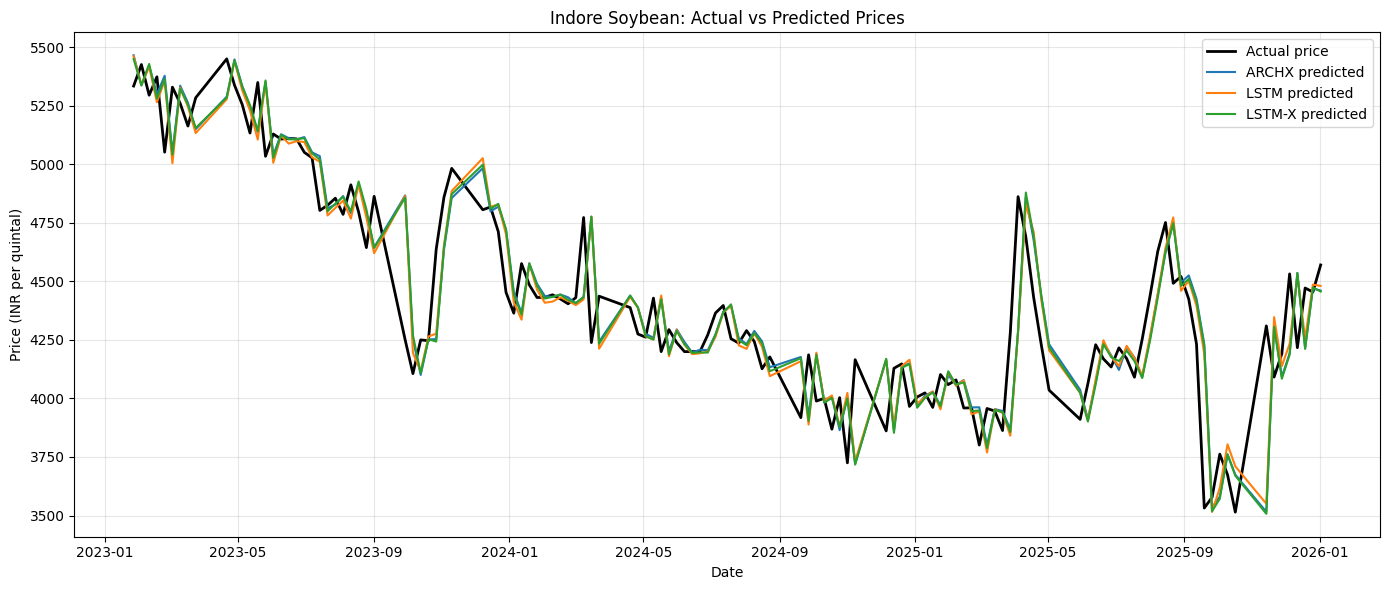

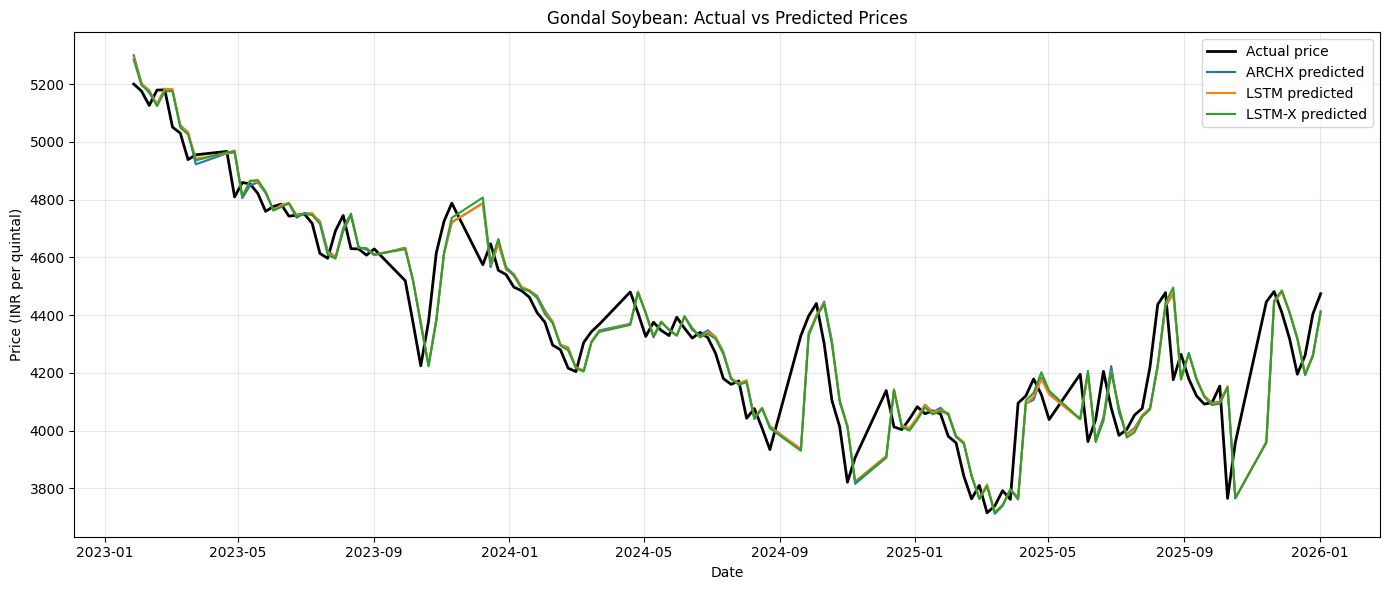

Graphs saved in: /content/soybean_graphs
Graph files: ['gondal_actual_vs_predicted.png', 'indore_actual_vs_predicted.png']


In [13]:

import os
import zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find and extract the uploaded results ZIP
zip_path = "/content/soybean_forecasting_results.zip"
extract_dir = "/content/soybean_results_extracted"

if os.path.exists(zip_path):
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)
else:
    print("ZIP not found. Please upload soybean_forecasting_results.zip.")

# Find CSVs, including those inside subfolders
search_dir = Path(extract_dir)
if not search_dir.exists() or not list(search_dir.rglob("*.csv")):
    search_dir = Path("/content")

csv_files = {
    p.name: p for p in search_dir.rglob("*.csv")
}

print("Found prediction files:")
for name in sorted(csv_files):
    if "predictions" in name:
        print(name)

# Generate actual vs predicted graphs
graph_dir = "/content/soybean_graphs"
os.makedirs(graph_dir, exist_ok=True)

models = {
    "ARCHX": "archx_predictions.csv",
    "LSTM": "lstm_predictions.csv",
    "LSTM-X": "lstm_x_predictions.csv"
}

for market in ["indore", "gondal"]:
    plt.figure(figsize=(14, 6))
    plotted = False

    # Actual prices from the LSTM prediction file
    actual_file = f"{market}_lstm_predictions.csv"

    if actual_file not in csv_files:
        print(f"Missing file: {actual_file}")
        plt.close()
        continue

    base = pd.read_csv(csv_files[actual_file])
    base["date"] = pd.to_datetime(base["date"])
    base = base.sort_values("date")

    plt.plot(
        base["date"], base["actual_price"],
        label="Actual price", color="black", linewidth=2
    )
    plotted = True

    for model, suffix in models.items():
        filename = f"{market}_{suffix}"

        if filename not in csv_files:
            print(f"Skipping missing model file: {filename}")
            continue

        df = pd.read_csv(csv_files[filename])
        df["date"] = pd.to_datetime(df["date"])
        df = df.sort_values("date")

        plt.plot(
            df["date"], df["predicted_price"],
            label=f"{model} predicted", linewidth=1.5
        )

    if plotted:
        plt.title(
            f"{market.title()} Soybean: Actual vs Predicted Prices"
        )
        plt.xlabel("Date")
        plt.ylabel("Price (INR per quintal)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        output_file = os.path.join(
            graph_dir, f"{market}_actual_vs_predicted.png"
        )
        plt.savefig(output_file, dpi=300, bbox_inches="tight")
        plt.show()

    plt.close()

print("Graphs saved in:", graph_dir)
print("Graph files:", os.listdir(graph_dir))


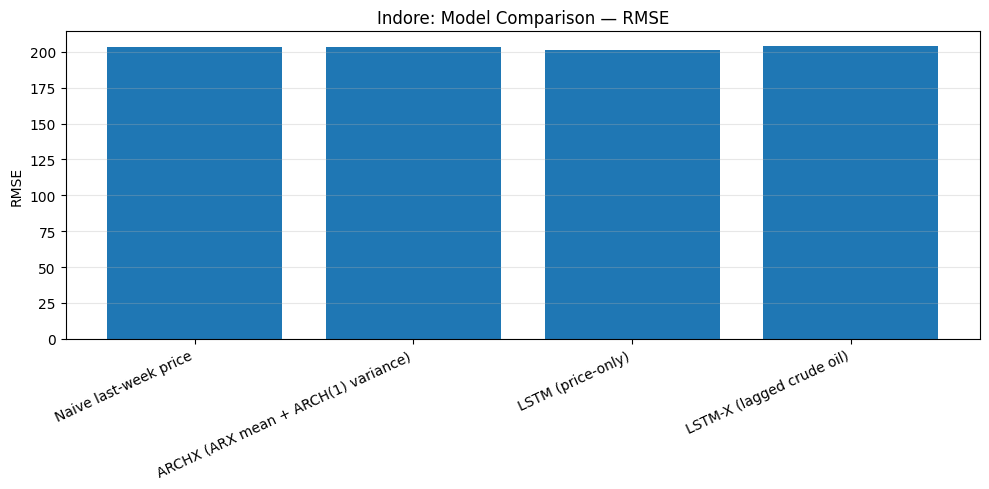

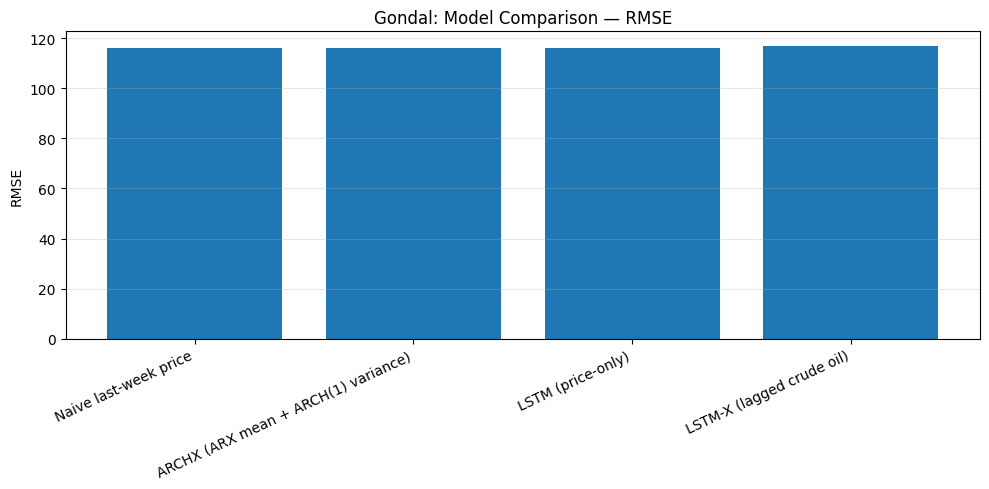

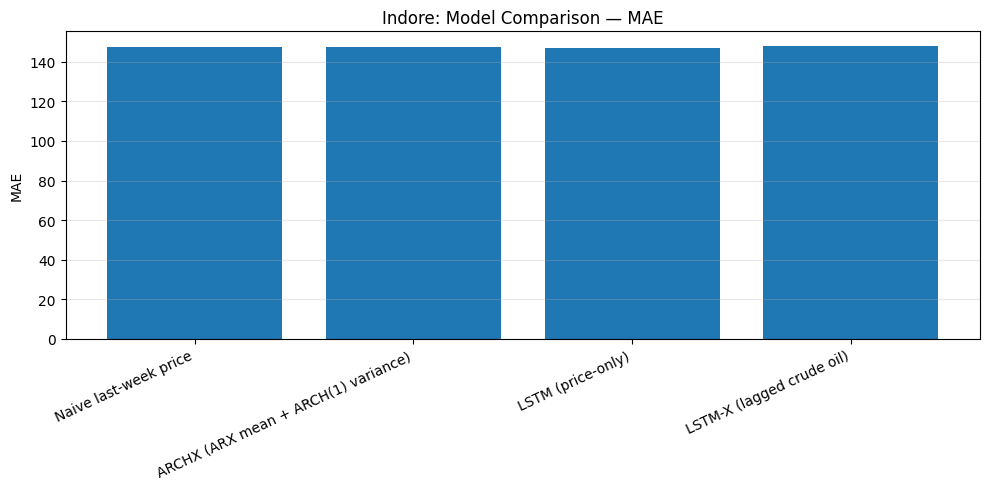

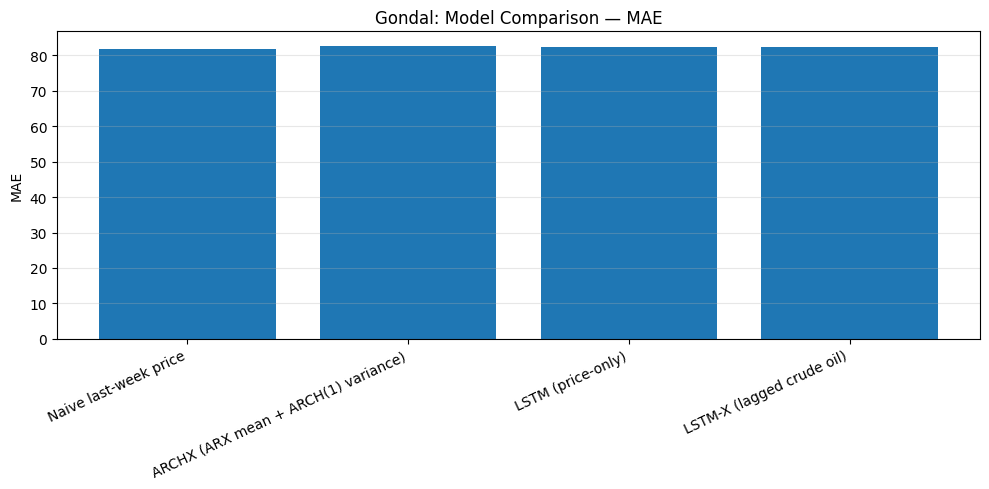

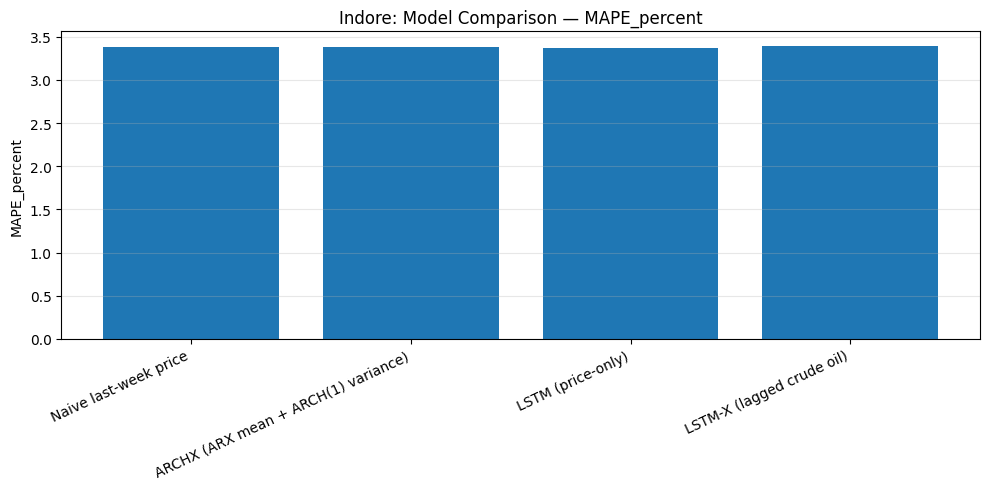

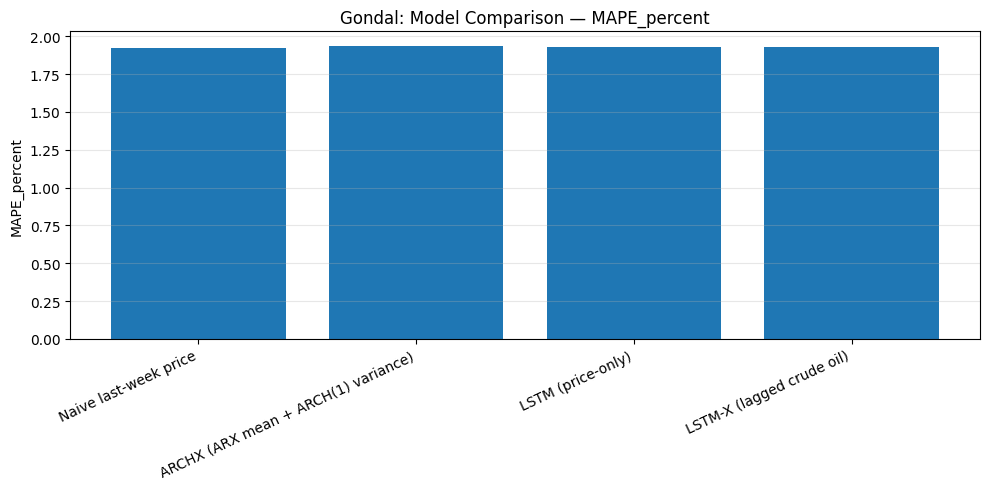

All comparison graphs saved.


In [14]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import os

metrics_path = next(
    Path("/content").rglob("out_of_sample_metrics.csv"),
    None
)

if metrics_path is None:
    raise FileNotFoundError(
        "Cannot find out_of_sample_metrics.csv. Extract the results ZIP first."
    )

metrics = pd.read_csv(metrics_path)
graph_dir = "/content/soybean_graphs"
os.makedirs(graph_dir, exist_ok=True)

for metric in ["RMSE", "MAE", "MAPE_percent"]:
    for market in ["Indore", "Gondal"]:
        subset = metrics[
            metrics["market"].str.lower() == market.lower()
        ]

        if subset.empty:
            continue

        plt.figure(figsize=(10, 5))
        plt.bar(subset["model"], subset[metric])
        plt.title(f"{market}: Model Comparison — {metric}")
        plt.ylabel(metric)
        plt.xticks(rotation=25, ha="right")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()

        filename = f"{market.lower()}_{metric.lower()}.png"
        plt.savefig(
            os.path.join(graph_dir, filename),
            dpi=300, bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("All comparison graphs saved.")


In [15]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/soybean_graphs",
    "zip",
    "/content/soybean_graphs"
)

files.download("/content/soybean_graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>